# Práctica visual — ¿Qué imagen elegirías?

**Objetivo:** elegir un producto de imagen según la pregunta de trabajo y explicar qué puede demostrar. Vamos a mirar una foto real del vuelo local, una escena satelital de la costa y otra escena de dron de Mendoza. El polígono amarillo es una zona de observación dibujada para esta actividad. La tarea es interpretar las imágenes; el código solo las abre, amplía y superpone.

**Recorrido:** 1) inspeccionar una captura; 2) observar qué agrega un mapa y ampliar un píxel; 3) comparar con una escena de dron; 4) decidir qué usar en cuatro pedidos. Los archivos se leen desde `assets/geospatial/`; no hay descargas ni procesamiento de un vuelo completo.

## 1. Mirar una captura real

Esta foto RGB pertenece al vuelo de Mendoza. Observá caminos, diferencias de tono del suelo y posibles sombras. **Pregunta:** ¿qué podés señalar visualmente? ¿Qué dato te faltaría para enviar a alguien a una planta específica?

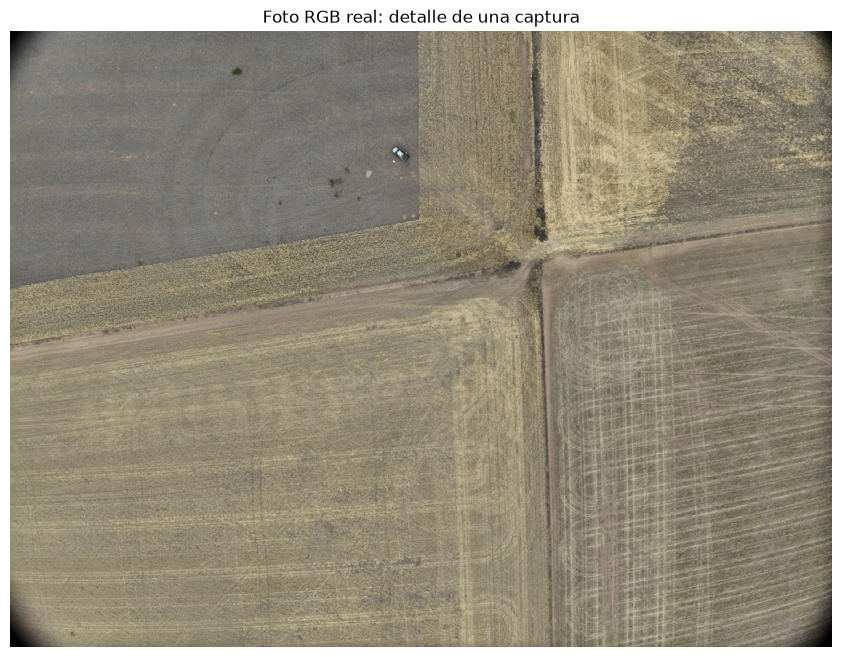

In [1]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

assets = Path("../../assets/geospatial") if Path("../../assets/geospatial").exists() else Path("assets/geospatial")
foto = Image.open(assets / "DCIM/DJI_202511151449_001_ellauquen-Lote1/DJI_20251115145153_0001_D.JPG")
vista = foto.copy()
vista.thumbnail((1200, 900))
plt.figure(figsize=(12, 8))
plt.imshow(vista)
plt.title("Foto RGB real: detalle de una captura")
plt.axis("off")
plt.show()

**Lectura guiada.** La foto ayuda a inspeccionar la apariencia de esa captura. Su GPS EXIF ubica la **cámara**, no cada píxel. La ilustración separa ambos conceptos:

![Foto real y ubicación de la cámara](../../media/clase_02/foto_real_y_gps.png)

**Anotá:** una observación visible, una interpretación posible y algo que todavía no podés verificar. Por ejemplo, ver hileras es una observación; llamar «maleza» a una planta exige evidencia adicional.

## 2. Ver qué agrega una imagen real preparada como mapa

Esta imagen de **Sentinel‑2A** muestra parte de la costa de Países Bajos. El mar, la playa y las áreas urbanizadas se distinguen a una escala de 10 m por píxel. Sus tonos RGB se ajustaron para verla en pantalla; no son valores de reflectancia para calcular índices.

El contorno amarillo es una **zona de observación didáctica**, dibujada para la clase. No es una parcela ni un límite oficial. El GeoJSON y la imagen tienen sistemas de coordenadas distintos; el notebook transforma el contorno para que aparezca en el lugar correcto.

**Pregunta:** ¿qué partes del mar, la costa y la ciudad quedan dentro de la zona amarilla?

Imagen: EPSG:32631 · píxel: 10 m
Zona de observación, transformada a: PROJCS["WGS 84 / UTM zone 31N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",3],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32631"]]


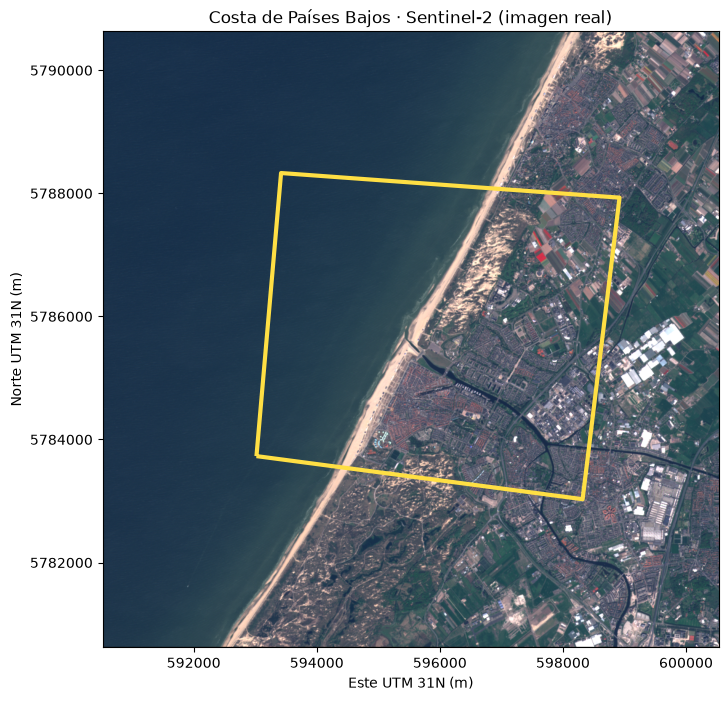

In [2]:
import rasterio
from rasterio.plot import show
import geopandas as gpd

zona = gpd.read_file(assets / "zona_observacion_costa.geojson")
fig, ax = plt.subplots(figsize=(8, 8))
with rasterio.open(assets / "costa_paises_bajos_sentinel2_rgb.tif") as escena:
    print(f"Imagen: {escena.crs} · píxel: {escena.res[0]:.0f} m")
    show(escena, ax=ax)
    zona = zona.to_crs(escena.crs)
print(f"Zona de observación, transformada a: {zona.crs}")
zona.boundary.plot(ax=ax, color="#ffdf44", linewidth=3)
ax.set_title("Costa de Países Bajos · Sentinel-2 (imagen real)")
ax.set_xlabel("Este UTM 31N (m)")
ax.set_ylabel("Norte UTM 31N (m)")
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
plt.show()

### Zoom: ¿qué guarda un píxel de esta imagen?

La vista completa deja reconocer mar, playa y ciudad. Ahora ampliamos un sector de la franja clara cercana a la costa hasta ver sus celdas. El recuadro amarillo marca **un píxel**. Antes de mirar los números, preguntate: ¿muestra un objeto único o resume lo que hay en una superficie de 10 m × 10 m?

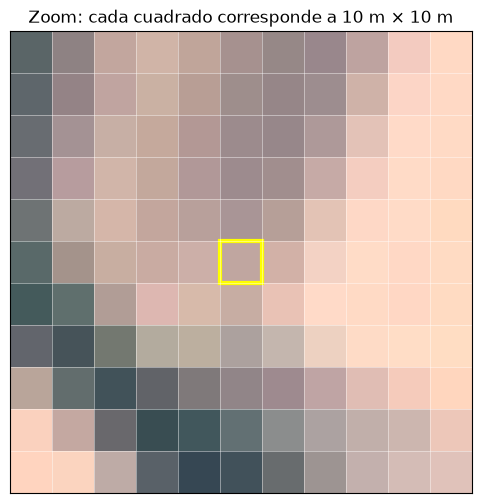

Píxel marcado: fila 500, columna 500
Centro en el mapa (EPSG:32631): Este 595525 m, Norte 5785625 m
Superficie representada: 10 m × 10 m
Color de pantalla (0–255): R=192, G=166, B=160


In [3]:
from matplotlib.patches import Rectangle

fila, columna, radio = 500, 500, 5
with rasterio.open(assets / "costa_paises_bajos_sentinel2_rgb.tif") as escena:
    recorte = escena.read(window=((fila-radio, fila+radio+1),
                                   (columna-radio, columna+radio+1))).transpose(1, 2, 0)
    rojo, verde, azul = recorte[radio, radio]
    este, norte = escena.xy(fila, columna)
    ancho, alto = escena.res

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(recorte, interpolation="nearest")
ax.add_patch(Rectangle((radio-.5, radio-.5), 1, 1,
                       fill=False, edgecolor="yellow", linewidth=3))
ax.set_xticks([i-.5 for i in range(12)], minor=True)
ax.set_yticks([i-.5 for i in range(12)], minor=True)
ax.grid(which="minor", color="white", linewidth=.5, alpha=.6)
ax.tick_params(which="both", bottom=False, left=False,
               labelbottom=False, labelleft=False)
ax.set_title("Zoom: cada cuadrado corresponde a 10 m × 10 m")
plt.show()
print(f"Píxel marcado: fila {fila}, columna {columna}")
print(f"Centro en el mapa (EPSG:32631): Este {este:.0f} m, Norte {norte:.0f} m")
print(f"Superficie representada: {ancho:.0f} m × {alto:.0f} m")
print(f"Color de pantalla (0–255): R={rojo}, G={verde}, B={azul}")

**Leé el resultado.** La fila y la columna ubican la celda **dentro del archivo**; Este y Norte ubican su centro **en el mapa**. Sus tres números RGB describen el color con que se muestra esa celda. En esta copia los tonos se ajustaron para pantalla: **no son reflectancia ni sirven para calcular NDVI**. Un píxel de 10 m × 10 m puede mezclar arena, vegetación, construcciones o sombras; el zoom agranda la visualización, pero no revela detalle nuevo.

**Conversen:** ¿qué cambió al ampliar la imagen y qué información sigue faltando para reconocer una planta o una maleza?

**Lectura guiada.** El ráster muestra una escena real con coordenadas; el polígono marca una zona que elegimos mirar. Juntos permiten decir qué partes visibles de mar, playa o ciudad caen dentro. La superposición tampoco convierte el contorno en un límite oficial ni permite identificar plantas individuales.

![Imagen y polígono son dos capas que se complementan](../../media/clase_02/raster_vs_vectorial.png)

**Fuente de la imagen:** [muestra GeoTIFF de Sentinel‑2A](https://github.com/mommermi/geotiff_sample). *Contains modified Copernicus Sentinel data 2020.* El repositorio de origen indica 2020; el archivo no trae una fecha de captura más precisa. [Condiciones de uso](https://cds.climate.copernicus.eu/licences/ec-sentinel).

## 3. Mismo tamaño de terreno, distinto detalle

Volvamos a Mendoza con una escena de dron de **AgroCam**, diferente del vuelo de la primera demostración. La ficha indica una captura del **15 de febrero de 2019** y una resolución cercana a **5 cm por píxel**. Primero mirá la escena completa; el recuadro amarillo señala un recorte de aproximadamente **10 m × 10 m** sobre las hileras, que aparece ampliado a la derecha.

**Antes de mirar:** un píxel de la imagen Sentinel‑2 cubre 10 m × 10 m. ¿Cuántos píxeles de 5 cm entran a lo largo de uno de sus lados? ¿Qué detalles esperarías distinguir?

Imagen de dron: 5.0 cm por píxel


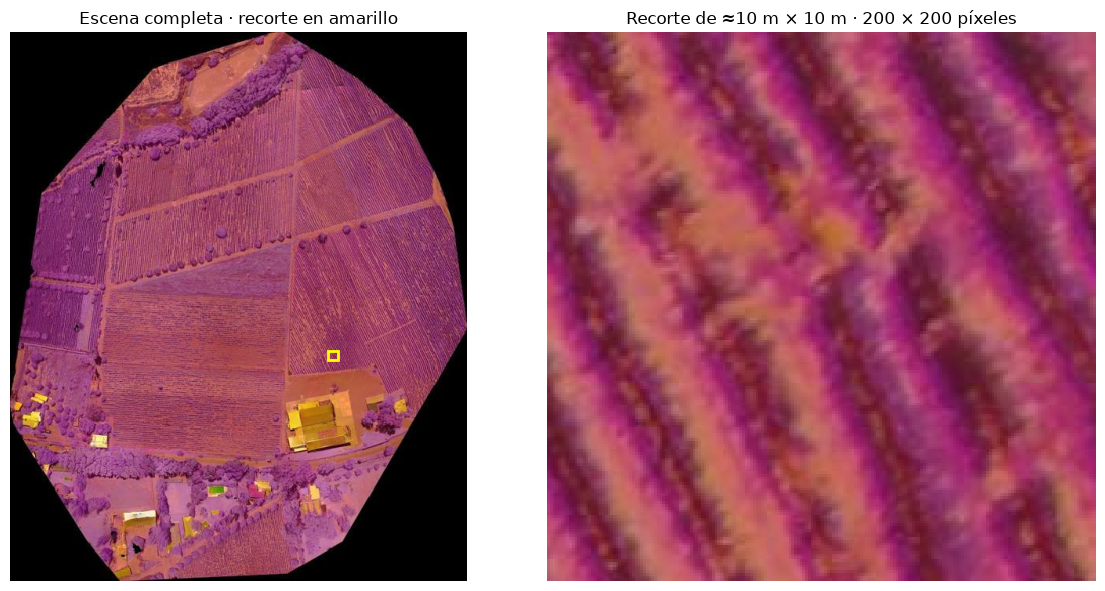

In [4]:
from rasterio.enums import Resampling
from rasterio.windows import Window
from matplotlib.patches import Rectangle

with rasterio.open(assets / "mendoza_agrocam_20190215.tif") as dron:
    alto = 700
    ancho = round(dron.width * alto / dron.height)
    vista_dron = dron.read(out_shape=(3, alto, ancho),
                           resampling=Resampling.nearest).transpose(1, 2, 0)
    detalle = dron.read(window=Window(6400, 6400, 200, 200)).transpose(1, 2, 0)
    escala = alto / dron.height
    print(f"Imagen de dron: {dron.res[0]*100:.1f} cm por píxel")

fig, ejes = plt.subplots(1, 2, figsize=(12, 6))
ejes[0].imshow(vista_dron)
ejes[0].add_patch(Rectangle((6400*escala, 6400*escala), 200*escala, 200*escala,
                            fill=False, edgecolor="yellow", linewidth=2))
ejes[0].set_title("Escena completa · recorte en amarillo")
ejes[1].imshow(detalle, interpolation="nearest")
ejes[1].set_title("Recorte de ≈10 m × 10 m · 200 × 200 píxeles")
for eje in ejes:
    eje.axis("off")
plt.tight_layout()
plt.show()

**Compará las dos demostraciones.** Un píxel de Sentinel‑2 y el recorte del dron representan superficies de alrededor de **10 m × 10 m**. En la imagen de dron esa superficie contiene **200 × 200 píxeles**: se distinguen las hileras y diferencias dentro del sector que la muestra Sentinel‑2 resumiría en una sola celda. Son lugares y fechas distintos; la comparación muestra **escala espacial**, no un cambio real entre escenas.

**Anotá:** dos cosas que observás en el recorte y una interpretación que todavía necesitaría comprobarse en campo. Los tonos violetas y anaranjados de esta visualización no permiten identificar por sí solos cultivos, malezas ni un índice de vegetación; la ficha no explica las bandas de esos colores.

**Fuente y licencia:** [AgroCam, escena de Mendoza en OpenAerialMap](https://imagery.hotosm.org/browse?lat=-33.0513&lon=-68.8196&zoom=16.8&selected_id=5c68285a00b30100059fc421), 15/02/2019, [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). El GeoTIFF local es una copia de la escena; el notebook reduce su vista completa para pantalla y recorta un sector sin reinterpretar los valores.

## 4. Elegí el producto para cada pedido

Usá estas opciones: **foto RGB de dron**, **ortomosaico georreferenciado con parcela**, **serie satelital** o **producto multiespectral preparado**. En cada respuesta agregá una razón y un límite.

| Pedido | Mi elección | ¿Por qué? | ¿Qué no puedo concluir todavía? |
|---|---|---|---|
| Observar si se distinguen hileras y suelo en una captura de hoy. |  |  |  |
| Entregar la ubicación de una zona para revisar en campo. |  |  |  |
| Comparar cobertura entre fechas en varios lotes. |  |  |  |
| Explorar una respuesta espectral que RGB no muestra. |  |  |  |

**Pistas para discutir:** la foto ofrece detalle local; el ortomosaico permite ubicar observaciones si su posición fue validada; la serie satelital facilita seguir cambios a mayor escala; las bandas multiespectrales amplían lo que se mide. Ninguna de estas elecciones, por sí sola, confirma malezas.

Volvé a la [clase 2](clase_02.md) para revisar los criterios y sus fuentes.